In [5]:
from typing_extensions import TypedDict, NotRequired
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    topic: str

initial_state: State = {
    "topic": "Agentic AI"
}

print(initial_state)

{'topic': 'Agentic AI'}


In [6]:
#Noding the state graph
def research_node(state: State) -> dict:
    topic = state["topic"]

    research = (
        f"Research about {topic}: "
        "definition, applications, and risks."
    )

    return {"research": research}

In [7]:
result = research_node(initial_state)
print(result)

{'research': 'Research about Agentic AI: definition, applications, and risks.'}


Now inherit multiple nodes with edges to create a state graph

In [8]:
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver

class State(TypedDict):
    topic: str
    research: NotRequired[str]
    summary: NotRequired[str]
    approved: NotRequired[bool]
    result: NotRequired[str]

In [10]:
#1)
def research_node(state: State) -> dict:
    topic = state["topic"]

    research = (
        f"Key points about {topic}: "
        "(1) definition "
        "(2) use-cases "
        "(3) risks."
    )

    print("Research completed!")
    return {"research": research}

#2)
def summarize_node(state: State) -> dict:
    research = state["research"]
    topic = state["topic"]

    summary = (
        f"Summary: {research} "
        f"In short, {topic} is useful but needs guardrails."
    )

    print("Summary generated!")
    return {"summary": summary}

#3)
def approval_node(state: State) -> Command:
    decision = interrupt({
        "question": "Approve this summary? (yes/no)",
        "topic": state["topic"],
        "summary": state["summary"],
        "expected_format": {"approved": "yes|no"}
    })

    approved = (
        str(decision.get("approved", "")).strip().lower() == "yes"
    )

    return Command(
        goto="save",
        update={"approved": approved}
    )

In [ ]:
def save_node(state: State) -> dict:
    if not state.get("approved", False):
        print("Summary rejected. Nothing saved.")
        return {"result": "Not approved — nothing saved."}

    import os
    path = "output/output.txt"
    if not os.path.exists("output"):
        os.makedirs("output") 

    with open(path, "w", encoding="utf-8") as f:
        f.write(f"TOPIC: {state['topic']}\n\n")
        f.write(state["summary"] + "\n")

    print("Summary saved!")
    return {"result": f"Saved to {path}"}

Build graph exactly

In [12]:
builder = StateGraph(State)

builder.add_node("research", research_node)
builder.add_node("summarize", summarize_node)
builder.add_node("approve", approval_node)
builder.add_node("save", save_node)

builder.add_edge(START, "research")
builder.add_edge("research", "summarize")
builder.add_edge("summarize", "approve")
builder.add_edge("save", END)

print("Graph structure defined!")

Graph structure defined!


In [13]:
checkpointer = InMemorySaver()

graph = builder.compile(
    checkpointer=checkpointer
)

print("Graph compiled successfully!")

Graph compiled successfully!


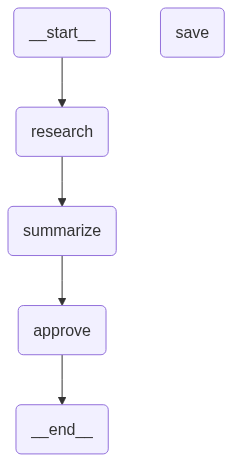

In [14]:
#mermaid visualization
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
user_input = input("Enter your question or topic: ")
print("Your input:", user_input)

Your input: what is rag in ai?


In [17]:
from uuid import uuid4

config = {
    "configurable": {
        "thread_id": str(uuid4())
    }
}

output = graph.invoke(
    {"topic": user_input},
    config=config
)

print("Approval required:")
print(output["__interrupt__"][0].value)

Research completed!
Summary generated!
Approval required:
{'question': 'Approve this summary? (yes/no)', 'topic': 'what is rag in ai?', 'summary': 'Summary: Key points about what is rag in ai?: (1) definition (2) use-cases (3) risks. In short, what is rag in ai? is useful but needs guardrails.', 'expected_format': {'approved': 'yes|no'}}


In [18]:
decision = input("Approve this summary? (yes/no): ").strip().lower()

output = graph.invoke(
    Command(resume={"approved": decision}),
    config=config
)

print("\nFinal result:")
print(output.get("result"))

Summary saved!

Final result:
Saved to .output/output.txt
